# Learning to generate: executable lab
ES 667 · Nipun Batra · IIT Gandhinagar

45–60 minutes. CPU, offline procedural binary glyphs. Run from the repository root or notebooks folder. See LAB.md for student questions and ANSWERS.md after attempting them.

In [1]:
from pathlib import Path
import sys, json, subprocess, math
import torch
from torch.nn import functional as F
ROOT = Path.cwd() if (Path.cwd()/"src/math.mjs").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT/"notebooks"))
from models import TinyVAE, vae_step, sample_vae, make_image_gan, gan_step
from train import glyphs
from validate import validate
torch.set_num_threads(2)
torch.manual_seed(667)
print("PyTorch", torch.__version__)

PyTorch 2.13.0


## 1. Shared exact quantities
The JavaScript module is the same module used by the lecture. Compare both KL directions and explain the posterior gap.

In [2]:
fixture = json.loads(subprocess.check_output(["node", str(ROOT/"src/math.mjs")]))
print(json.dumps(fixture, indent=2))
assert abs(fixture["finite"]["elbo"] + fixture["finite"]["gap"] - fixture["finite"]["logEvidence"]) < 1e-10

{
  "kl": 0.09151622184943578,
  "reverseKL": 0.10464962875290948,
  "entropy": 0.5004024235381879,
  "crossEntropy": 0.5919186453876236,
  "finite": {
    "prior": [
      0.5,
      0.5
    ],
    "likelihood": [
      0.8,
      0.2
    ],
    "q": [
      0.6,
      0.4
    ],
    "evidence": 0.5,
    "posterior": [
      0.8,
      0.2
    ],
    "reconstruction": -0.777661295762166,
    "priorKL": 0.020135513550688863,
    "elbo": -0.7977968093128549,
    "gap": 0.10464962875290948,
    "logEvidence": -0.6931471805599453
  },
  "reparam": {
    "mu": 1,
    "sigma": 0.5,
    "epsilon": -0.4,
    "a": 0,
    "z": 0.8,
    "loss": 0.6400000000000001,
    "dmu": 1.6,
    "dsigma": -0.6400000000000001,
    "dlogvar": -0.16000000000000003
  },
  "vae": {
    "x": [
      1,
      0
    ],
    "mu": [
      1,
      -1
    ],
    "sigma": [
      0.5,
      1
    ],
    "epsilon": [
      0.2,
      -0.4
    ],
    "pi": [
      0.75,
      0.25
    ],
    "z": [
      1.1,
      -1.4


## 2. One pathwise derivative
Keep epsilon fixed. Then compare many samples with the expected gradient.

In [3]:
mu = torch.tensor(1., dtype=torch.float64, requires_grad=True)
logvar = torch.tensor(math.log(.25), dtype=torch.float64, requires_grad=True)
eps = torch.tensor(-.4, dtype=torch.float64)
z = mu + (logvar/2).exp()*eps
loss = z.square()
loss.backward()
print("sample, loss, dmu, dlogvar:", z.item(), loss.item(), mu.grad.item(), logvar.grad.item())
assert abs(mu.grad.item()-1.6)<1e-10
assert abs(logvar.grad.item()+.16)<1e-10

sample, loss, dmu, dlogvar: 0.8 0.6400000000000001 1.6 -0.16000000000000003


In [4]:
mu.grad = None; logvar.grad = None
eps = torch.randn(10000, generator=torch.Generator().manual_seed(19), dtype=torch.float64)
((mu + (logvar/2).exp()*eps).square().mean()).backward()
print("estimated gradients:", mu.grad.item(), logvar.grad.item())
print("exact expected gradients:", 2*mu.item(), logvar.exp().item())

estimated gradients: 2.003904531756472 0.25238052705681935
exact expected gradients: 2.0 0.25


## 3. Train one VAE step and inspect the recorded model
This short step is a smoke demonstration. The saved model below was trained for 65 epochs. Displaying decoder probabilities differs from sampling its Bernoulli likelihood.

In [5]:
model = TinyVAE()
x = glyphs(128)
optimizer = torch.optim.Adam(model.parameters(), lr=.001)
print("one fresh update:", vae_step(model, optimizer, x))
model.load_state_dict(torch.load(ROOT/"models/vae.pt", map_location="cpu", weights_only=True))
with torch.no_grad():
    mu, logvar = model.encode(x[:8])
    reconstruction = model.decode(mu).sigmoid().reshape(-1,1,28,28)
    probabilities = sample_vae(model, count=8, sample_pixels=False)
    binary_samples = sample_vae(model, count=8, sample_pixels=True)
print(reconstruction.shape, probabilities.shape, binary_samples.unique().tolist())

one fresh update: {'loss': 549.7880859375, 'recon': 549.7572631835938, 'kl': 0.030847132205963135}
torch.Size([8, 1, 28, 28]) torch.Size([8, 1, 28, 28]) [0.0, 1.0]


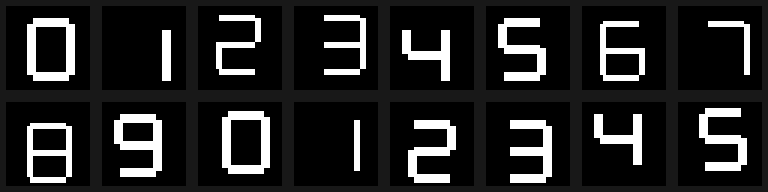

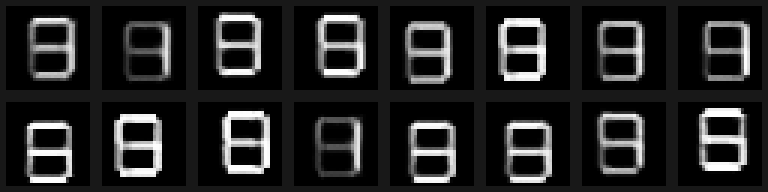

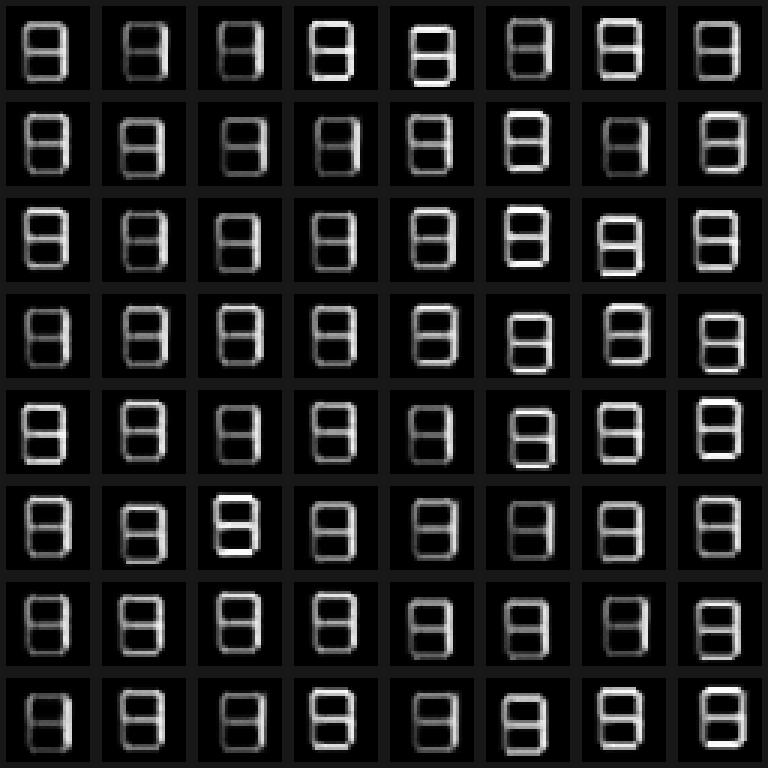

In [6]:
from IPython.display import display, Image
display(Image(filename=str(ROOT/"assets/recorded/held-out.png")))
display(Image(filename=str(ROOT/"assets/recorded/reconstructions.png")))
display(Image(filename=str(ROOT/"assets/recorded/vae-prior.png")))

## 4. Alternating GAN updates
Run the real gradient-isolation checks. They include the deliberately broken detach diagnostic. Inspect the complete `gan_step` function in models.py.

In [7]:
G,D = make_image_gan()
optG = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(.5,.999))
optD = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(.5,.999))
print(gan_step(G,D,optG,optD,glyphs(16)))
report = validate()
assert report["passed"] == 14

{'D': 1.3705990314483643, 'G': 0.7682505249977112}
{
  "passed": 14,
  "checks": [
    "pathwise autograd matches shared module",
    "VAE shapes B=3",
    "VAE reduction semantics B=3",
    "GAN and target shapes B=3",
    "VAE shapes B=17",
    "VAE reduction semantics B=17",
    "GAN and target shapes B=17",
    "prior generation bypasses encoder",
    "D phase leaves G parameters and gradients unchanged",
    "D phase updates D",
    "frozen D still transmits nonzero gradient to G",
    "G phase changes only G",
    "broken G detach removes the gradient graph",
    "two-pixel PyTorch loss agrees with shared fixtures"
  ],
  "torch": "2.13.0",
  "fixtures_source": "src/math.mjs",
  "executed": true
}


In [8]:
run = json.loads((ROOT/"assets/recorded/gan.json").read_text())
for frame in run["frames"]:
    points = torch.tensor(frame["samples"])
    centres = torch.tensor([[-2.,0.],[2.,0.]])
    close = torch.cdist(points,centres) < .65
    print(frame["step"], "realism", close.any(1).float().mean().item(), "coverage", (close.sum(0)>=5).sum().item(), frame["loss"])

0 realism 0.0 coverage 0 {'D': None, 'G': None}
1 realism 0.0 coverage 0 {'D': 1.3699114322662354, 'G': 0.6250135898590088}
10 realism 0.0 coverage 0 {'D': 1.3163156509399414, 'G': 0.6369686722755432}
50 realism 0.078125 coverage 1 {'D': 1.0462766885757446, 'G': 0.8980664014816284}
100 realism 0.21875 coverage 2 {'D': 1.3685181140899658, 'G': 0.8708211183547974}
200 realism 0.2578125 coverage 2 {'D': 1.3553471565246582, 'G': 0.7455605864524841}
400 realism 0.62890625 coverage 2 {'D': 1.2789478302001953, 'G': 0.8449041843414307}
800 realism 0.88671875 coverage 2 {'D': 1.370330572128296, 'G': 0.7700408101081848}
1200 realism 0.91015625 coverage 2 {'D': 1.4027761220932007, 'G': 0.7561047077178955}
1800 realism 0.94140625 coverage 2 {'D': 1.4372732639312744, 'G': 0.6935508251190186}


## Optional full rerun
Run `python notebooks/train.py --epochs 65 --steps 1800` from the repository root. This replaces the recorded artifacts with a fresh seeded run. Training time and bitwise results can vary by environment. No GPU or paid API is needed.

**Exit:** explain why a plausible sample is insufficient evidence of distribution coverage.